# End-to-End Quantum Track Reconstruction — the QSVT polynomial filter (the comb)

This notebook demonstrates the **QSVT** solver lane of the LHCb VELO toy model, the
follow-up to the one-bit quantum filter (1BQF):

1. **Response functions** — what the 1BQF cosine and the QSVT polynomial do to the spectrum
2. **The comb on a small clean event** — three exact backends of the same circuit agree
3. **The three realisations** — LCU of walk powers (the build), the phase sequence (QSVT proper), QETU
4. **A moderate event** — classical vs 1BQF vs QSVT: activation spectra, efficiency-first working points, tracks
5. **Scaling with track count** — segment efficiency and false rate against $T$
6. **Other response families** — normalized comb, the one-bit cosine as a series, the trigonometric comb
7. **Refitting the coefficients** to a measured event, and the event-to-event transfer

### What the QSVT is here
A function of the segment Hamiltonian acts mode by mode, $f(A)\,b = \sum_j f(\lambda_j)\beta_j u_j$.
The 1BQF applies one cosine, $f(\lambda)=\cos(\lambda t/2)$: a single zero at the isolated-segment
line $\lambda = s = \gamma+\delta$. The QSVT applies **any bounded polynomial** $p(A)$ of degree $d$,
built as a linear combination of Chebyshev polynomials $T_k(X)$ of the qubitization walk operator,
$\langle 0|W^k|0\rangle = T_k(X)$ — the 1BQF cosine is the degree-one member of the family.

**"The QSVT" (the comb)** = the degree-40 *line comb*: narrow $\sim 1/\lambda$ passes at the four
true-track eigenvalue lines $s - 2\cos(k\pi/5)$ and $\approx 0$ everywhere else. Variants are
distinguished only by the polynomial degree and by the Hamiltonian (base $A$, $A$ + fork term,
$A$ + occupancy term).

`QSVT(A, b)` builds the comb by default (`QSVT.comb(A, b)` is the explicit spelling); the
retired band design and the other families are selected with `filter_design=`.

USED as a starting point for al my notebooks. 

In [22]:
# ── imports ──────────────────────────────────────────────────────
import time
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from lhcb_velo_toy.generation import PlaneGeometry, StateEventGenerator
from lhcb_velo_toy.solvers import SimpleHamiltonianFast, get_tracks
from lhcb_velo_toy.solvers.quantum import (
    QSVT, design_line_comb_inverse, design_band_limited_inverse, design_minimax_comb,
    design_one_bit_cosine, design_normalized_comb, solve_normalized_comb, design_trig_comb,
    one_bit_response, p4_lines, solve_one_bit_matrixfree,
    mode_system, apply_response, spectral_bounds,
    chebyshev_moments, refit_coefficients,
)
from lhcb_velo_toy.analysis import (
    EventValidator, compute_epsilon, truth_from_event,
    threshold_for, metrics_at, quantum_metrics_wp, metrics_at_wp,
)
from lhcb_velo_toy.analysis.working_points import rescale_to_signal
from lhcb_velo_toy.analysis.plotting.event_display import plot_event_3d, plot_reco_vs_truth

%matplotlib inline
plt.rcParams["figure.dpi"] = 110

# ── the house set-up: 5 planes, dz = 33 mm, gamma = 3, delta = 1 ─────────
N_MODULES, DZ = 5, 33.0
GAMMA, DELTA = 3.0, 1.0
S = GAMMA + DELTA                       # the constant diagonal of A
TAU_ABS = threshold_for(GAMMA, DELTA)   # 0.35: the classical fixed cut (diagnostic only)

def make_geometry(n_modules=N_MODULES, dz=DZ, half=50.0):
    return PlaneGeometry(module_id=list(range(n_modules)), lx=[half]*n_modules,
                         ly=[half]*n_modules, z=[100.0 + i*dz for i in range(n_modules)])

def generate_event(n_tracks, measurement_error=0.0, collision_noise=1e-8, seed=0):
    gen = StateEventGenerator(detector_geometry=make_geometry(), events=1,
                              n_particles=[n_tracks], measurement_error=measurement_error,
                              collision_noise=collision_noise, seed=seed)
    gen.generate_random_primary_vertices({"x": 0, "y": 0, "z": 0})
    gen.generate_particles([[{"type": "pion", "mass": 139.6, "q": 1}] * n_tracks])
    gen.generate_complete_events()
    return gen

def build_system(gen, measurement_error, collision_noise):
    eps = compute_epsilon(measurement_error, collision_noise, dz=DZ)
    ham = SimpleHamiltonianFast(epsilon=eps, gamma=GAMMA, delta=DELTA)
    A, b = ham.construct_hamiltonian(gen)
    return ham, A, b, eps

print("All imports successful.  s =", S, " fixed classical cut =", TAU_ABS)

All imports successful.  s = 4.0  fixed classical cut = 0.35


---
## 1. Response functions

Everything below is a choice of $f(\lambda)$. The geometry pins complete true tracks to the four
$P_4$ lines $s-2\cos(k\pi/5)$ (green); the failure modes sit on the isolated line $\lambda=s$
(grey), the pair lines $s\pm1$ and the triple lines $s\pm\sqrt2$ (red).

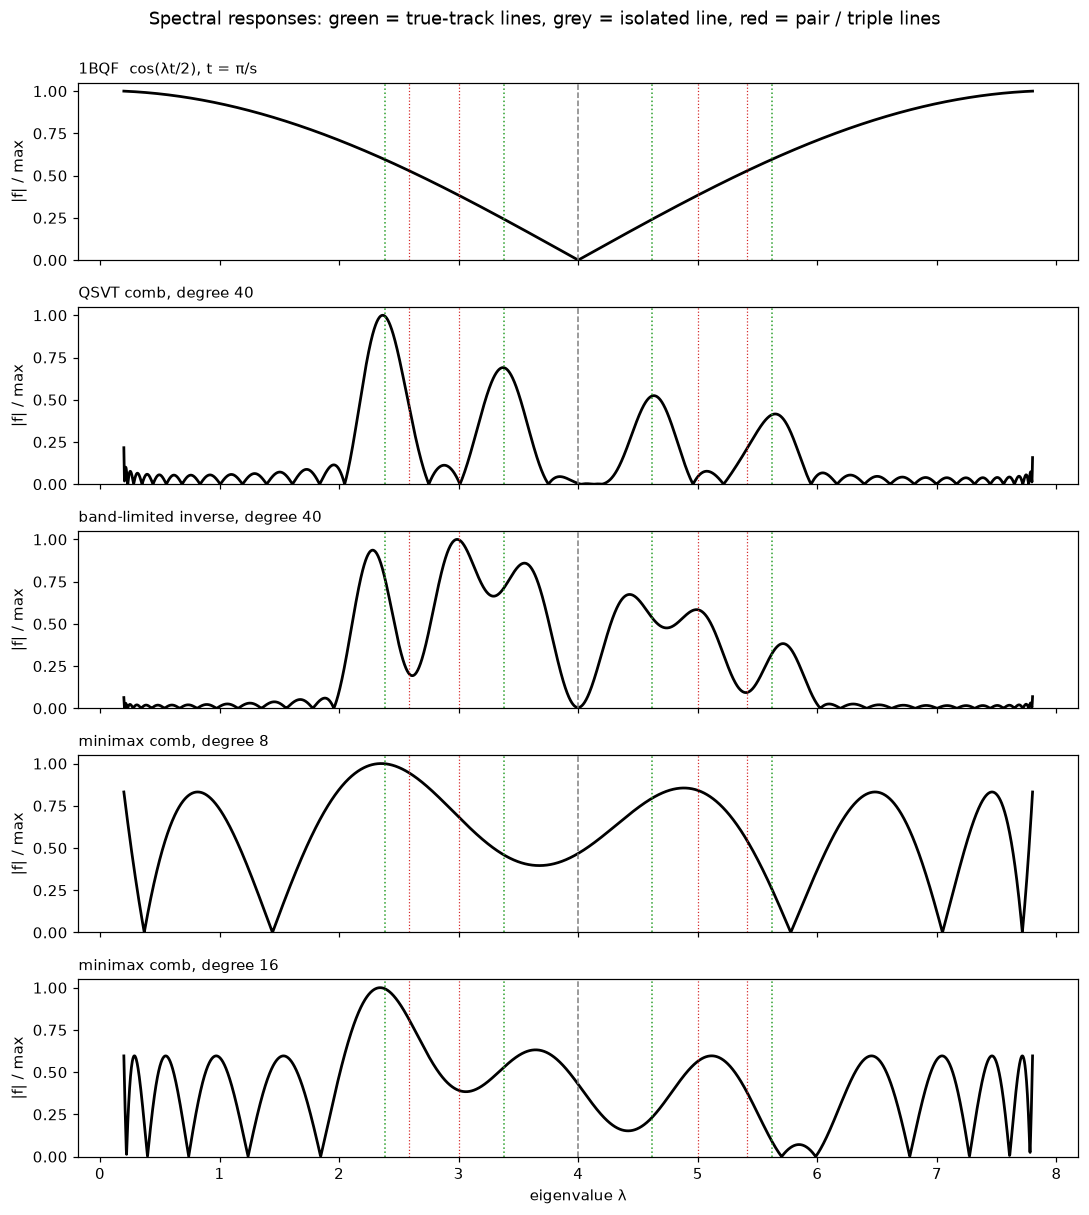

In [23]:
lam = np.linspace(0.2, 7.8, 3000)
responses = {
    "1BQF  cos(λt/2), t = π/s":           one_bit_response(S)(lam),
    "QSVT comb, degree 40":               np.abs(design_line_comb_inverse(40, s=S)(lam)),
    "band-limited inverse, degree 40":    np.abs(design_band_limited_inverse(40, s=S)(lam)),
    "minimax comb, degree 8":             np.abs(design_minimax_comb(8, s=S)(lam)),
    "minimax comb, degree 16":            np.abs(design_minimax_comb(16, s=S)(lam)),
}
fig, axes = plt.subplots(len(responses), 1, figsize=(10, 2.2*len(responses)), sharex=True)
for ax, (name, y) in zip(axes, responses.items()):
    ax.plot(lam, y / y.max(), lw=1.8, color="k")
    for m in p4_lines(S): ax.axvline(m, color="tab:green", ls=":", lw=1)
    ax.axvline(S, color="grey", ls="--", lw=1)
    for m in (S-1, S+1, S-np.sqrt(2), S+np.sqrt(2)): ax.axvline(m, color="tab:red", ls=":", lw=0.8)
    ax.set_ylabel("|f| / max"); ax.set_title(name, fontsize=10, loc="left"); ax.set_ylim(0, 1.05)
axes[-1].set_xlabel("eigenvalue λ")
fig.suptitle("Spectral responses: green = true-track lines, grey = isolated line, red = pair / triple lines", y=1.0)
fig.tight_layout(); plt.show()

---
## 2. The comb on a small clean event — three backends of one circuit

`solve_statevector` (Chebyshev recursion, sparse matvecs, scales to millions of segments),
`solve_eigh` (one per-component eigendecomposition, reusable for many responses) and
`run_circuit(streaming=True)` (the explicit LCU-of-walk-powers circuit, gate by gate) must
agree: they are three evaluations of the same post-selected state $p(X)|b\rangle/\|c\|_1$.

In [24]:
gen3 = generate_event(3, seed=11)
ham3, A3, b3, eps3 = build_system(gen3, 0.0, 1e-8)
truth3 = truth_from_event(gen3)
x_cls3 = np.abs(ham3.solve_classicaly())
print(f"T = 3 clean event: {ham3.n_segments} segments, {int(truth3.sum())} true, ε = {eps3*1e3:.3f} mrad")

q3 = QSVT(A3, b3, degree=40)                            # the QSVT of the papers: the comb (the default)
t0 = time.time(); sol_sv, p_sv = q3.solve_statevector(); t_sv = time.time() - t0
t0 = time.time(); sol_ei, p_ei = q3.solve_eigh();        t_ei = time.time() - t0
t0 = time.time(); sol_ci, p_ci = q3.run_circuit(streaming=True); t_ci = time.time() - t0
try:
    t0 = time.time(); sol_qk, p_qk = q3.run_circuit(streaming=False); t_qk = time.time() - t0
    qk_line = f"| qiskit circuit (`run_circuit()`) | {p_qk:.6f} | {np.max(np.abs(sol_qk - sol_sv)):.1e} | {t_qk:.2f} |\n"
except ImportError:
    qk_line = "| qiskit circuit (`run_circuit()`) | qiskit not installed | | |\n"
display(Markdown(
    "| backend | success probability | max amplitude difference to statevector | time (s) |\n"
    "|---|---|---|---|\n"
    f"| matrix-free recursion (`solve_statevector`) | {p_sv:.6f} | — | {t_sv:.3f} |\n"
    f"| per-component eigh (`solve_eigh`) | {p_ei:.6f} | {np.max(np.abs(sol_ei - sol_sv)):.1e} | {t_ei:.3f} |\n"
    f"| streamed circuit (`run_circuit(streaming=True)`) | {p_ci:.6f} | {np.max(np.abs(sol_ci - sol_sv)):.1e} | {t_ci:.2f} |\n"
    + qk_line))
r = q3.resources()
print(f"width: {r['system_qubits']} system + {r['ancillas']} ancilla = {r['total_qubits']} qubits; "
      f"{r['calls_per_shot']} walk steps per shot as built ({r['walk_calls']} with an optimal SELECT); "
      f"||c||_1 = {r['l1']:.3f}, max|p| = {r['peak']:.3f}, LCU penalty (||c||_1/max|p|)^2 = {r['lcu_penalty']:.2f}")

T = 3 clean event: 36 segments, 12 true, ε = 0.021 mrad


| backend | success probability | max amplitude difference to statevector | time (s) |
|---|---|---|---|
| matrix-free recursion (`solve_statevector`) | 0.146596 | — | 0.000 |
| per-component eigh (`solve_eigh`) | 0.146596 | 3.3e-16 | 0.002 |
| streamed circuit (`run_circuit(streaming=True)`) | 0.146596 | 1.1e-16 | 0.00 |
| qiskit circuit (`run_circuit()`) | 0.146596 | 2.0e-15 | 0.16 |


width: 6 system + 7 ancilla = 13 qubits; 63 walk steps per shot as built (40 with an optimal SELECT); ||c||_1 = 0.514, max|p| = 0.349, LCU penalty (||c||_1/max|p|)^2 = 2.17


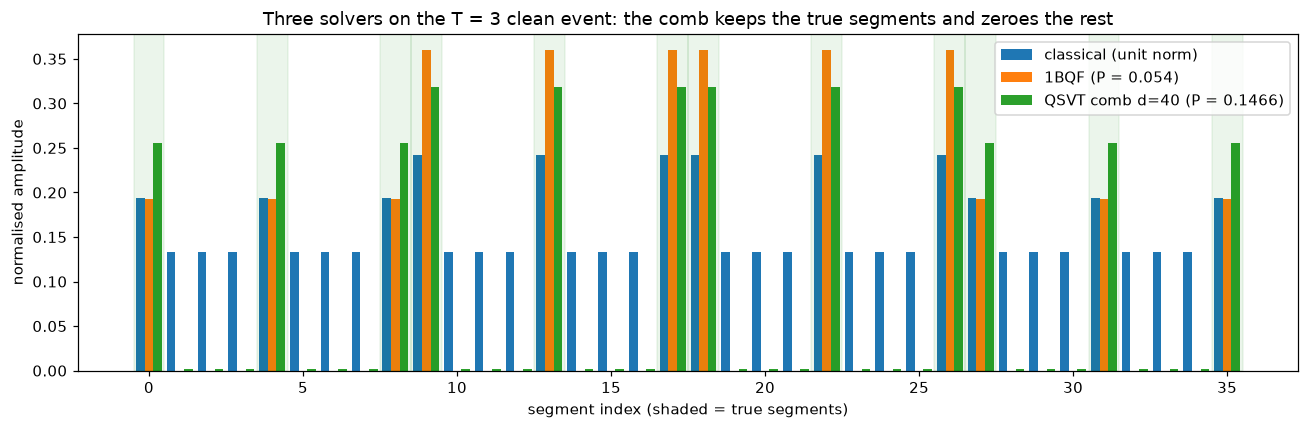

In [25]:
sol_1b3, p_1b3, _ = solve_one_bit_matrixfree(A3)
idx = np.arange(ham3.n_segments); w = 0.28
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(idx - w, x_cls3 / np.linalg.norm(x_cls3), w, label="classical (unit norm)", color="tab:blue")
ax.bar(idx,     sol_1b3, w, label=f"1BQF (P = {p_1b3:.3f})", color="tab:orange")
ax.bar(idx + w, sol_sv,  w, label=f"QSVT comb d=40 (P = {p_sv:.4f})", color="tab:green")
for i in np.flatnonzero(truth3): ax.axvspan(i - 0.5, i + 0.5, color="green", alpha=0.08)
ax.set_xlabel("segment index (shaded = true segments)"); ax.set_ylabel("normalised amplitude")
ax.set_title("Three solvers on the T = 3 clean event: the comb keeps the true segments and zeroes the rest")
ax.legend(); fig.tight_layout(); plt.show()

---
## 3. The three realisations

The response is one thing; the circuit that applies it is a choice (paper section 4.2):

| realisation | primitive | ancillas | calls per shot | success probability |
|---|---|---|---|---|
| LCU of walk powers (the build) | block encoding | $1+m$ | $2^m-1$ ($d$ with an optimal SELECT) | $\|p(X)u\|^2/\|c\|_1^2$ |
| phase sequence (QSVT proper) | block encoding | 4 (3 for definite parity) | $4d$ ($2d$) | $\|q(X)u\|^2/(\alpha_e+\alpha_o)^2$, $q=p/\max\lvert p\rvert$ |
| trigonometric comb (QETU) | $e^{-iAt}$ | 2 | $K$ | $\|p_{\rm trig}(A)u\|^2$ |

`solve_phase_sequence` runs the phase sequence as dense linear algebra: the comb is split into
even and odd parts, symmetric phase factors are found for each (seconds at low degree, minutes
at degree 40), and both sequences are run on the dilation block encoding and recombined.

In [26]:
q12 = QSVT.comb(A3, b3, degree=12)
sol_lcu, p_lcu = q12.solve_statevector()
t0 = time.time(); sol_ph, p_ph = q12.solve_phase_sequence(); t_ph = time.time() - t0
info = q12.phase_info
print(f"degree-12 comb on the T = 3 event: phases found in {t_ph:.1f} s")
print(f"  scalar-identity error  even {info['max_err']['even']:.1e}, odd {info['max_err']['odd']:.1e}")
print(f"  max |amplitude difference| phase sequence vs LCU: {np.max(np.abs(sol_ph - sol_lcu)):.1e}")
print(f"  success probability: LCU {p_lcu:.4f}, phase sequence {p_ph:.4f} "
      f"(ratio {p_ph/p_lcu:.2f} = (||c||_1/max|p|)^2 / (α_e+α_o)^2 = "
      f"{q12.resources('phase')['lcu_penalty']:.2f} / {info['parity_penalty']:.3f})")

rt = q3.resource_table()
display(Markdown(
    "**Resources of the degree-40 comb on this event, by realisation**\n\n"
    "| realisation | ancillas | total qubits | calls per shot |\n|---|---|---|---|\n"
    + "\n".join(f"| {k} | {v['ancillas']} | {v['total_qubits']} | {v['calls_per_shot']} |" for k, v in rt.items())))

degree-12 comb on the T = 3 event: phases found in 1.1 s
  scalar-identity error  even 4.2e-07, odd 1.8e-07
  max |amplitude difference| phase sequence vs LCU: 3.4e-08
  success probability: LCU 0.1877, phase sequence 0.3898 (ratio 2.08 = (||c||_1/max|p|)^2 / (α_e+α_o)^2 = 2.09 / 1.007)


**Resources of the degree-40 comb on this event, by realisation**

| realisation | ancillas | total qubits | calls per shot |
|---|---|---|---|
| lcu | 7 | 13 | 63 |
| phase | 4 | 10 | 160 |
| qetu | 2 | 8 | 40 |

In [27]:
# ── the phase factors themselves (what solve_phase_sequence found above) ─────
from numpy.polynomial import chebyshev as npcheb
from lhcb_velo_toy.solvers.quantum import (
    parity_split, find_phase_factors, apply_phase_sequence,
)

parts = parity_split(q12.coeffs)          # the comb has no definite parity: split it
print(f"comb rescaled by 1/{parts['scale']:.4f} to peak at 1 "
      f"(the phase sequence may do this; the one-norm route may not)")
print(f"  even part peaks at {parts['alpha_e']:.4f}, odd at {parts['alpha_o']:.4f}")
print(f"  recombination penalty (alpha_e + alpha_o)^2 = {parts['parity_penalty']:.4f}"
      "  <- what the parity split costs in success probability\n")

phases = {}
for name, coef in (("even", parts["ce"]), ("odd", parts["co"])):
    t0 = time.time()
    phis, err = find_phase_factors(coef)       # symmetric phase factors, L-BFGS-B
    phases[name] = phis
    print(f"  {name:4s}: {len(phis):2d} phases found in {time.time() - t0:5.1f} s, "
          f"max |Re<0|U_Phi(x)|0> - q(x)| = {err:.1e}")

# run ONE parity part on the dense block encoding and compare against q(X)u directly
X3, u3 = q12.X.toarray(), q12.b_norm
psi = apply_phase_sequence(X3, u3, phases["even"])
w3, V3 = np.linalg.eigh(X3)
ref_even = (V3 * npcheb.chebval(w3, parts["ce"])) @ V3.T @ u3
print(f"\ndense phase-sequence circuit vs q_even(X)u: "
      f"max abs difference {np.max(np.abs(psi.real - ref_even)):.2e}")
print("(the imaginary part is the complementary polynomial, discarded by the real-part trick)")

comb rescaled by 1/0.1526 to peak at 1 (the phase sequence may do this; the one-norm route may not)
  even part peaks at 0.7172, odd at 0.2863
  recombination penalty (alpha_e + alpha_o)^2 = 1.0071  <- what the parity split costs in success probability

  even: 13 phases found in   0.8 s, max |Re<0|U_Phi(x)|0> - q(x)| = 4.2e-07
  odd : 12 phases found in   0.3 s, max |Re<0|U_Phi(x)|0> - q(x)| = 1.8e-07

dense phase-sequence circuit vs q_even(X)u: max abs difference 7.59e-08
(the imaginary part is the complementary polynomial, discarded by the real-part trick)


---
## 4. A moderate event: classical, 1BQF and QSVT side by side

A 50-track event with 10 µm measurement error and multiple scattering ($\epsilon$ from the
closed-form formula). The three solvers are compared through the **efficiency-first working
point**: for every solver, the threshold is placed so that 99 % of the true segments stay active
and the false rate at that point is reported (`quantum_metrics_wp`). The classical fixed cut
$\tau = 0.35$ is shown as a diagnostic only: on filtered spectra it chops genuine true segments.

Read the table with the **floor** in mind: a few true segments of this event have lost their
partner to the acceptance window (a kink larger than $\epsilon$) and sit on the isolated line
$\lambda = s$ — the same eigenvalue as an isolated false segment. No spectral response can tell
them apart (the spectral-twin theorem), so *every* solver pays the same false rate when the
working point is forced to admit them (the 99 % rows). The 95 % rows sit above the floor and
separate the solvers: the 1BQF's cosine halving of the track-end segments pulls its threshold
into the false band, the comb's does not.

T = 50 moderate event: 640000 segments, 1600 true, ε = 3.18 mrad, nnz(A) = 643698
classical 49.2 ms | 1BQF matrix-free 1.82 s (20+2 qubits, P = 0.0006) | QSVT comb 246.0 ms (27 qubits, P = 0.00111)


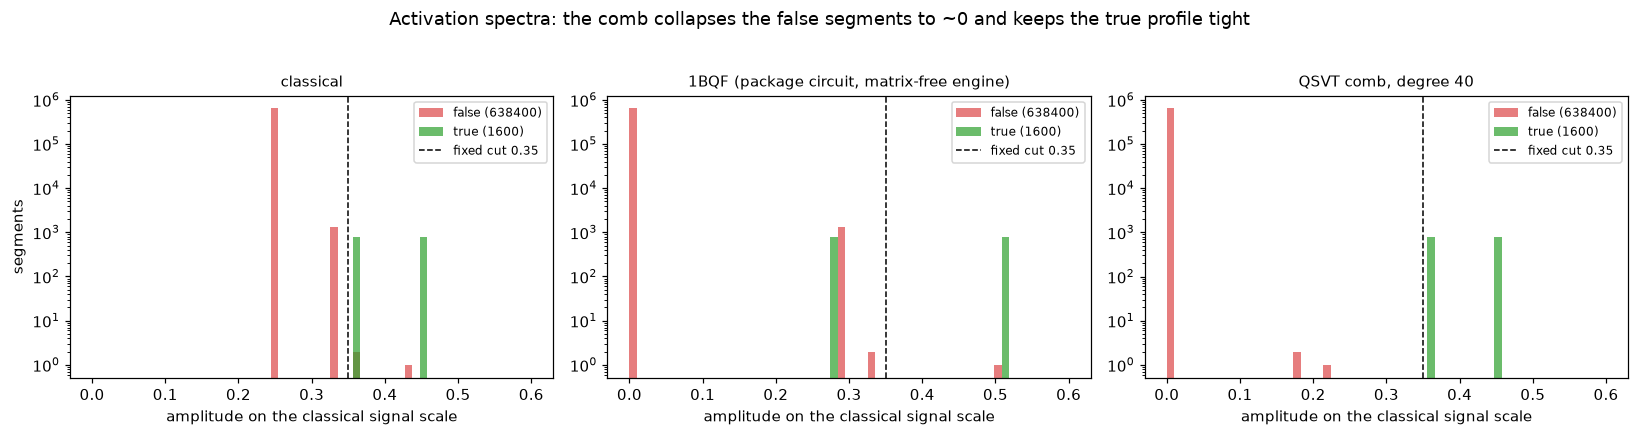

In [28]:
ME, CN = 0.01, 1e-4
gen20 = generate_event(400, ME, CN, seed=202)
ham20, A20, b20, eps20 = build_system(gen20, ME, CN)
truth20 = truth_from_event(gen20)
n20 = ham20.n_segments
print(f"T = 50 moderate event: {n20} segments, {int(truth20.sum())} true, ε = {eps20*1e3:.2f} mrad, "
      f"nnz(A) = {A20.nnz}")

t0 = time.time(); x_cls = np.abs(ham20.solve_classicaly()); t_cls = time.time() - t0
t0 = time.time(); x_1b, p_1b, nsys_1b = solve_one_bit_matrixfree(A20); t_1b = time.time() - t0
q20 = QSVT.comb(A20, b20, degree=40, spectral_bounds=spectral_bounds(A20))
t0 = time.time(); x_qs, p_qs = q20.solve_statevector(); t_qs = time.time() - t0
print(f"classical {t_cls*1e3:.1f} ms | 1BQF matrix-free {t_1b:.2f} s ({nsys_1b}+2 qubits, P = {p_1b:.4f}) | "
      f"QSVT comb {t_qs*1e3:.1f} ms ({q20.total_qubits} qubits, P = {p_qs:.5f})")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=False)
for ax, (name, x) in zip(axes, [("classical", x_cls),
                                ("1BQF (package circuit, matrix-free engine)", rescale_to_signal(x_1b, x_cls)),
                                ("QSVT comb, degree 40", rescale_to_signal(x_qs, x_cls))]):
    bins = np.linspace(0, max(0.6, x.max()*1.02), 60)
    ax.hist(x[~truth20], bins, color="tab:red", alpha=0.6, label=f"false ({int((~truth20).sum())})", log=True)
    ax.hist(x[truth20],  bins, color="tab:green", alpha=0.7, label=f"true ({int(truth20.sum())})", log=True)
    ax.axvline(TAU_ABS, color="k", ls="--", lw=1, label="fixed cut 0.35")
    ax.set_title(name, fontsize=10); ax.set_xlabel("amplitude on the classical signal scale"); ax.legend(fontsize=8)
axes[0].set_ylabel("segments")
fig.suptitle("Activation spectra: the comb collapses the false segments to ~0 and keeps the true profile tight", y=1.03)
fig.tight_layout(); plt.show()

In [29]:
rows = []
m = metrics_at(x_cls, truth20, TAU_ABS);           rows.append(("classical, fixed τ = 0.35", m, np.nan))
m = metrics_at_wp(x_cls, truth20);                 rows.append(("classical, efficiency-first (99 %)", m, m["tau_wp"]))
m = quantum_metrics_wp(x_1b, x_cls, truth20);      rows.append(("1BQF, efficiency-first (99 %)", m, m["tau_wp"]))
m = quantum_metrics_wp(x_qs, x_cls, truth20);      rows.append(("QSVT comb d=40, efficiency-first (99 %)", m, m["tau_wp"]))
keys = list(rows[0][1].keys())
eff_k, far_k = "segment_efficiency", "segment_false_rate"
tab = "| solver / working point | segment efficiency | false rate | threshold |\n|---|---|---|---|\n"
for name, m, tau in rows:
    tab += f"| {name} | {m[eff_k]:.4f} | {m[far_k]:.4f} | {'—' if np.isnan(tau) else f'{tau:.3f}'} |\n"
for name, x in (("classical", x_cls), ("1BQF", x_1b), ("QSVT comb d=40", x_qs)):
    m = quantum_metrics_wp(x, x_cls, truth20, target_eff=0.95)
    rows.append((f"{name}, efficiency-first (95 %)", m, m["tau_wp"]))
tab = "| solver / working point | segment efficiency | false rate | threshold |\n|---|---|---|---|\n"
for name, m, tau in rows:
    tab += f"| {name} | {m[eff_k]:.4f} | {m[far_k]:.4f} | {'—' if np.isnan(tau) else f'{tau:.3f}'} |\n"
display(Markdown(tab))

| solver / working point | segment efficiency | false rate | threshold |
|---|---|---|---|
| classical, fixed τ = 0.35 | 1.0000 | 0.0019 | — |
| classical, efficiency-first (99 %) | 1.0000 | 0.0006 | 0.364 |
| 1BQF, efficiency-first (99 %) | 1.0000 | 0.4477 | 0.275 |
| QSVT comb d=40, efficiency-first (99 %) | 1.0000 | 0.0000 | 0.365 |
| classical, efficiency-first (95 %) | 1.0000 | 0.0006 | 0.364 |
| 1BQF, efficiency-first (95 %) | 1.0000 | 0.4477 | 0.275 |
| QSVT comb d=40, efficiency-first (95 %) | 1.0000 | 0.0000 | 0.365 |


true segments the comb puts at ~0 (acceptance floor): 0 of 1600
QSVT threshold at the 95 % working point: 0.365 (classical fixed cut 0.35)


| track-level metric | classical (τ = 0.35) | QSVT comb (95 % working point) |
|---|---|---|
| reconstructed tracks | 397 | 400 |
| efficiency | 0.990 | 1.000 |
| ghost rate | 0.003 | 0.000 |
| clone fraction | 0.000 | 0.000 |
| mean purity | 1.000 | 1.000 |


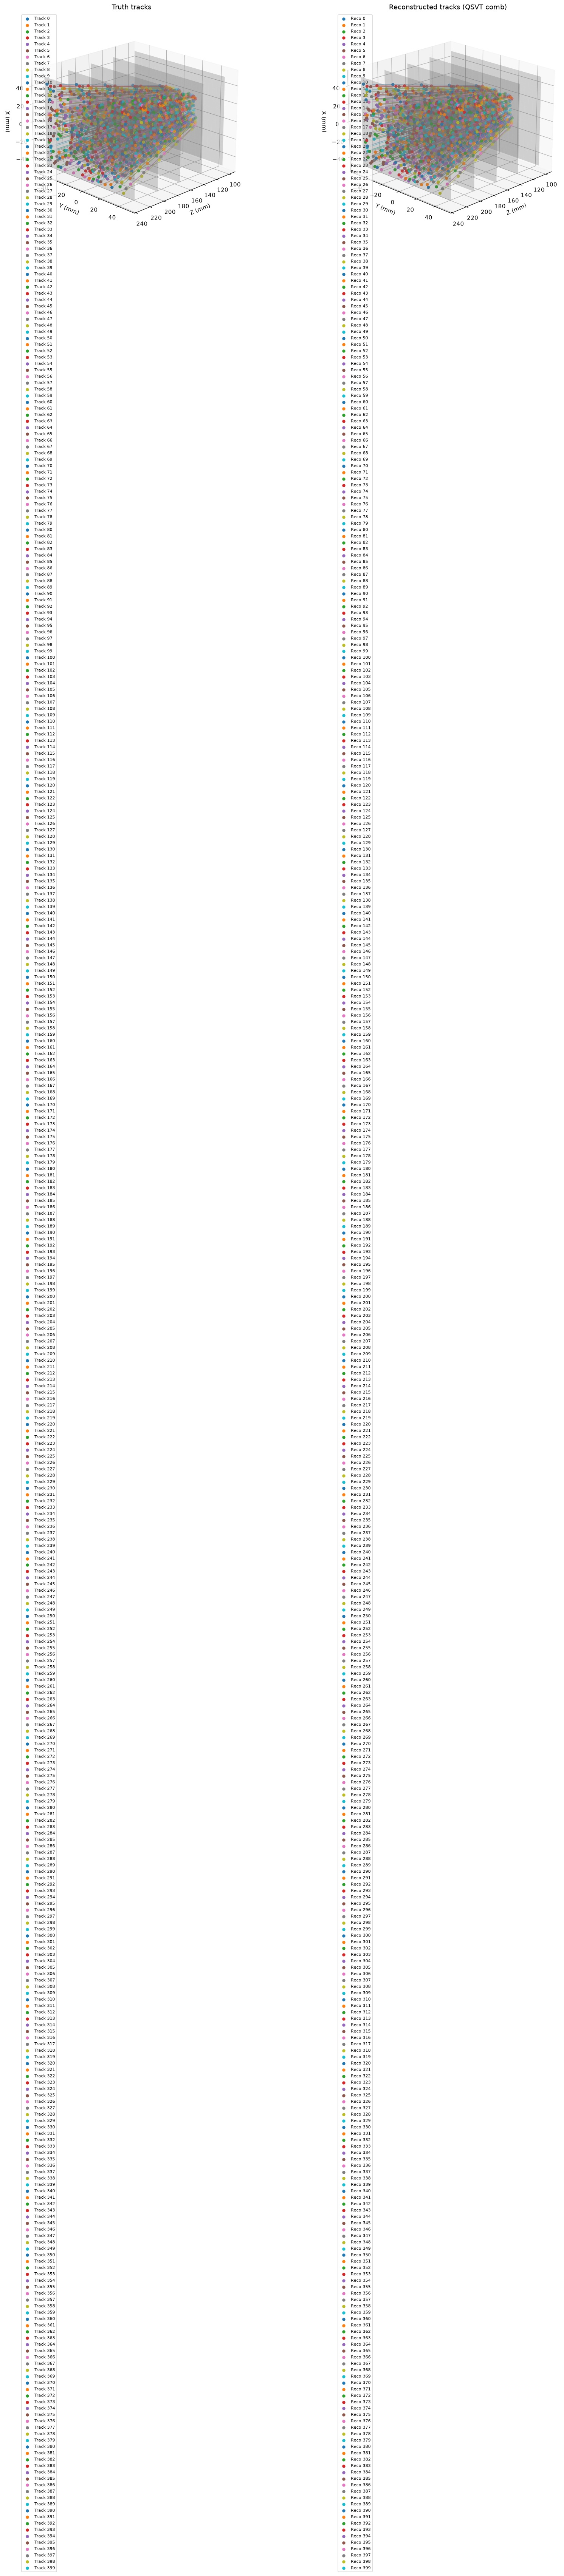

In [30]:
# ── tracks from the QSVT solution at its own efficiency-first threshold ──────
# The 99 % point on this event lies inside the acceptance floor (see above): about 3 % of
# the true segments sit at ~0 for the comb, so any target above ~97 % collapses the threshold
# to ~0 and admits the floor's false twins.  For track extraction use the 95 % working point,
# which clears the floor and lands inside the comb's true band.
x_qs_scaled = rescale_to_signal(x_qs, x_cls)
n_floor = int((rescale_to_signal(x_qs, x_cls)[truth20] < 0.05).sum())
tau_qs = quantum_metrics_wp(x_qs, x_cls, truth20, target_eff=0.95)["tau_wp"]
reco_qs = get_tracks(ham20, x_qs_scaled, gen20, threshold=tau_qs)
reco_cl = get_tracks(ham20, x_cls, gen20, threshold=TAU_ABS)
print(f"true segments the comb puts at ~0 (acceptance floor): {n_floor} of {int(truth20.sum())}")
print(f"QSVT threshold at the 95 % working point: {tau_qs:.3f} (classical fixed cut {TAU_ABS})")
val_q = EventValidator(gen20.true_event, reco_qs); _, met_q = val_q.match_tracks(purity_min=0.7)
val_c = EventValidator(gen20.true_event, reco_cl); _, met_c = val_c.match_tracks(purity_min=0.7)
display(Markdown(
    "| track-level metric | classical (τ = 0.35) | QSVT comb (95 % working point) |\n|---|---|---|\n"
    f"| reconstructed tracks | {len(reco_cl)} | {len(reco_qs)} |\n"
    f"| efficiency | {met_c['efficiency']:.3f} | {met_q['efficiency']:.3f} |\n"
    f"| ghost rate | {met_c['ghost_rate']:.3f} | {met_q['ghost_rate']:.3f} |\n"
    f"| clone fraction | {met_c['clone_fraction']:.3f} | {met_q['clone_fraction']:.3f} |\n"
    f"| mean purity | {met_c['mean_purity']:.3f} | {met_q['mean_purity']:.3f} |\n"))
fig = plot_reco_vs_truth(gen20.true_event, reco_qs, title_truth="Truth tracks", title_reco="Reconstructed tracks (QSVT comb)")
plt.show()

---
## 5. Scaling with track count

Segment efficiency and false rate at the efficiency-first working point against the number of
tracks, one event per point (so the false-rate points scatter with the floor population of each
event), for the three solvers, plus the post-selection success probability
of the two quantum filters (the 1BQF's is order one; the comb's falls as $\sim 1/T$, the price of
the one-norm normalisation, and is what amplitude amplification pays back as $\sim\sqrt{T}$ rounds).

T=  5 n_seg=   100  far@99%: classical 0.0000  1BQF 0.0000  QSVT 0.0000 | P: 1BQF 0.045 QSVT 0.0880 | 14 qubits | 1BQF 0.0s QSVT 0ms
T= 10 n_seg=   400  far@99%: classical 0.0000  1BQF 0.0000  QSVT 0.0000 | P: 1BQF 0.022 QSVT 0.0440 | 16 qubits | 1BQF 0.0s QSVT 0ms
T= 20 n_seg=  1600  far@99%: classical 0.0000  1BQF 0.0000  QSVT 0.0000 | P: 1BQF 0.011 QSVT 0.0220 | 18 qubits | 1BQF 0.0s QSVT 0ms
T= 40 n_seg=  6400  far@99%: classical 0.0000  1BQF 0.0000  QSVT 0.0000 | P: 1BQF 0.006 QSVT 0.0110 | 20 qubits | 1BQF 0.0s QSVT 1ms
T= 60 n_seg= 14400  far@99%: classical 0.0000  1BQF 0.0164  QSVT 0.0000 | P: 1BQF 0.004 QSVT 0.0073 | 21 qubits | 1BQF 0.0s QSVT 2ms
T= 80 n_seg= 25600  far@99%: classical 0.0000  1BQF 0.0184  QSVT 0.0000 | P: 1BQF 0.003 QSVT 0.0055 | 22 qubits | 1BQF 0.0s QSVT 3ms
T=120 n_seg= 57600  far@99%: classical 0.0021  1BQF 0.0996  QSVT 0.0000 | P: 1BQF 0.002 QSVT 0.0037 | 23 qubits | 1BQF 0.1s QSVT 5ms


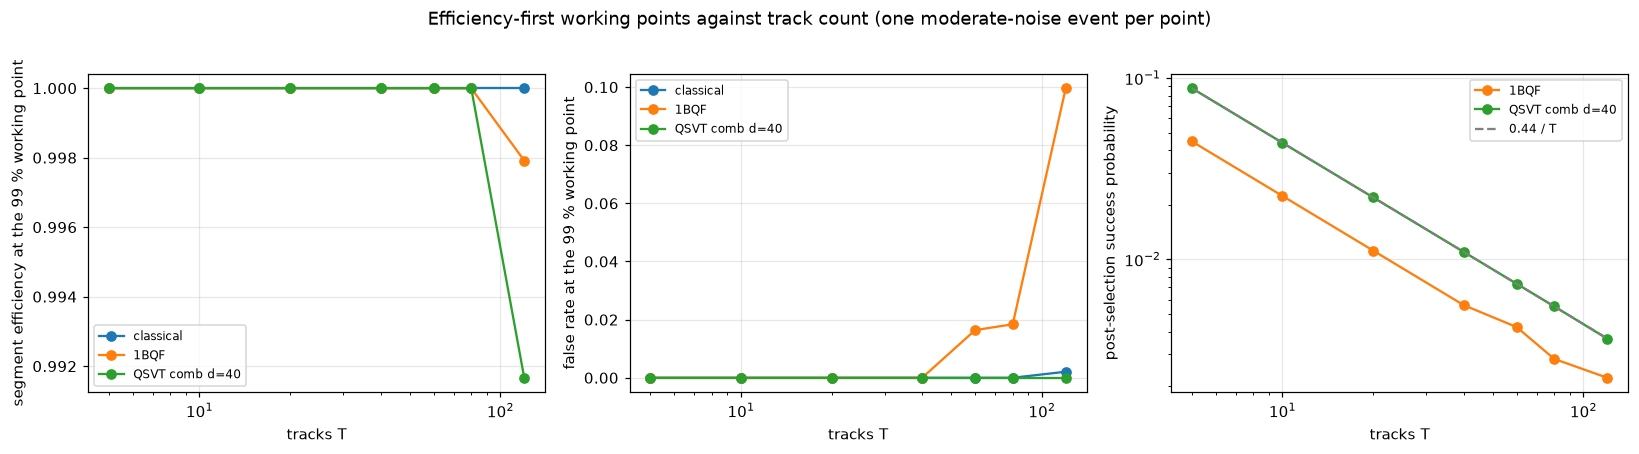

In [31]:
TS = [5, 10, 20, 40, 60, 80, 120]
scan = []
for T in TS:
    g = generate_event(T, ME, CN, seed=1000 + T)
    h, A, b, _ = build_system(g, ME, CN)
    tr = truth_from_event(g)
    xc = np.abs(h.solve_classicaly())
    t0 = time.time(); x1, p1, _ = solve_one_bit_matrixfree(A); t1 = time.time() - t0
    q = QSVT.comb(A, b, degree=40, spectral_bounds=spectral_bounds(A))
    t0 = time.time(); xq, pq = q.solve_statevector(); tq = time.time() - t0
    mc, m1, mq = metrics_at_wp(xc, tr), quantum_metrics_wp(x1, xc, tr), quantum_metrics_wp(xq, xc, tr)
    scan.append(dict(T=T, n=h.n_segments, eff_c=mc[eff_k], far_c=mc[far_k], eff_1=m1[eff_k], far_1=m1[far_k],
                     eff_q=mq[eff_k], far_q=mq[far_k], p1=p1, pq=pq, qubits_q=q.total_qubits, t1=t1, tq=tq))
    print(f"T={T:3d} n_seg={h.n_segments:6d}  far@99%: classical {mc[far_k]:.4f}  1BQF {m1[far_k]:.4f}  "
          f"QSVT {mq[far_k]:.4f} | P: 1BQF {p1:.3f} QSVT {pq:.4f} | {q.total_qubits} qubits | 1BQF {t1:.1f}s QSVT {tq*1e3:.0f}ms")

sc = {k: np.array([r[k] for r in scan]) for k in scan[0]}
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for key, lab, col in (("c", "classical", "tab:blue"), ("1", "1BQF", "tab:orange"), ("q", "QSVT comb d=40", "tab:green")):
    axes[0].plot(sc["T"], sc[f"eff_{key}"], "o-", color=col, label=lab)
    axes[1].plot(sc["T"], sc[f"far_{key}"], "o-", color=col, label=lab)
axes[2].semilogy(sc["T"], sc["p1"], "o-", color="tab:orange", label="1BQF")
axes[2].semilogy(sc["T"], sc["pq"], "o-", color="tab:green", label="QSVT comb d=40")
axes[2].semilogy(sc["T"], 0.44/sc["T"], "--", color="grey", label="0.44 / T")
axes[0].set_ylabel("segment efficiency at the 99 % working point"); axes[1].set_ylabel("false rate at the 99 % working point")
axes[2].set_ylabel("post-selection success probability")
for ax in axes: ax.set_xlabel("tracks T"); ax.set_xscale("log"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
fig.suptitle("Efficiency-first working points against track count (one moderate-noise event per point)", y=1.02)
fig.tight_layout(); plt.show()

---
## 6. Other response families

* **normalized comb** — the $\pm\tfrac12$ comb on the degree-normalised coupling $D^{-1/2}|C|D^{-1/2}$
  (the $\alpha=1$ block encoding of the Block-Encoding study): `solve_normalized_comb`.
* **the one-bit cosine as a series** — $|\cos(\pi\lambda/2s)|$ realised as a degree-60 Chebyshev series, so
  the 1BQF response runs through the same evaluator as the comb: `filter_design="cosine"`.
* **the trigonometric comb** — the comb as a cosine series in $\lambda t$ over the 1BQF's own primitive
  $e^{-iAt}$ (the QETU realisation, width $n_{\rm sys}+2$): `design_trig_comb` + `apply_response`.

All are compared on the T = 50 event at their own 95 % efficiency-first working point (above the floor).

| response | efficiency at the 95 % point | false rate | threshold |
|---|---|---|---|
| QSVT comb, degree 40 (LCU) | 1.0000 | 0.0000 | 0.365 |
| 1BQF package circuit (matrix-free) | 1.0000 | 0.4477 | 0.275 |
| one-bit |cos| response, exact (mode system) | 1.0000 | 0.0019 | 0.352 |
| one-bit |cos| as a degree-60 series | 1.0000 | 0.0019 | 0.352 |
| normalized ±½ comb, degree 40 | 1.0000 | 0.0000 | 0.344 |
| trigonometric comb, K = 40 (QETU response) | 1.0000 | 0.0000 | 0.364 |


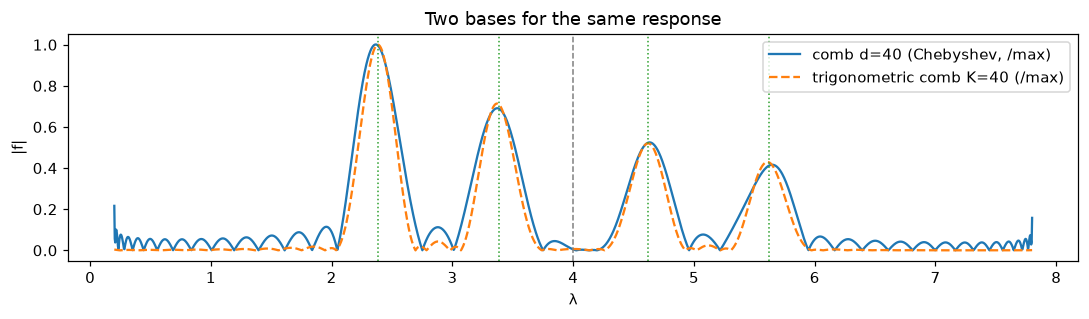

In [32]:
x_norm, p_norm = solve_normalized_comb(A20, degree=40)
x_cos, p_cos = QSVT(A20, b20, degree=60, filter_design="cosine", spectral_bounds=spectral_bounds(A20)).solve_statevector()
sysd20 = mode_system(A20, b20)
f_trig = design_trig_comb(K=40, s=S)
x_trig = apply_response(sysd20, f_trig)
x_exact_cos = apply_response(sysd20, one_bit_response(S))

fam = {"QSVT comb, degree 40 (LCU)": x_qs,
       "1BQF package circuit (matrix-free)": x_1b,
       "one-bit |cos| response, exact (mode system)": x_exact_cos,
       "one-bit |cos| as a degree-60 series": x_cos,
       "normalized ±½ comb, degree 40": x_norm,
       "trigonometric comb, K = 40 (QETU response)": x_trig}
tab = "| response | efficiency at the 95 % point | false rate | threshold |\n|---|---|---|---|\n"
for k, x in fam.items():
    v = quantum_metrics_wp(x, x_cls, truth20, target_eff=0.95)
    tab += f"| {k} | {v[eff_k]:.4f} | {v[far_k]:.4f} | {v['tau_wp']:.3f} |\n"
display(Markdown(tab))

lam = np.linspace(0.2, 7.8, 2000)
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(lam, np.abs(design_line_comb_inverse(40, s=S)(lam)) / 0.349, label="comb d=40 (Chebyshev, /max)")
ax.plot(lam, np.abs(f_trig(lam)), "--", label="trigonometric comb K=40 (/max)")
for m in p4_lines(S): ax.axvline(m, color="tab:green", ls=":", lw=1)
ax.axvline(S, color="grey", ls="--", lw=1); ax.set_xlabel("λ"); ax.set_ylabel("|f|"); ax.legend(); ax.set_title("Two bases for the same response")
fig.tight_layout(); plt.show()

---
## 7. Refitting the coefficients to a measured event (and transferring them)

The designed comb places its passes at the closed-form lines. On noisy events the populated
spectrum moves, and the paper's later sections replace the *target* step of the design by a
measurement: the Chebyshev coefficients become the unknowns of a ridge-regularised least-squares
fit that pushes the false amplitudes to zero while holding the true amplitudes to the classical
profile, with the ridge strength selected by the efficiency at a false-rate target. It is a
**supervised** fit (it needs the truth of the event it is fitted on); its uses are to measure
what a given degree can buy, and the event-to-event transfer test below.

> Status: the refit results are held back from the first paper until the refit audit and the
> transfer check close (QSVT catch-up, 3 Sep 2026). This is the audited code path.

| polynomial on the T = 50 event | efficiency at the 95 % point | false rate | ridge μ | selection score (eff at far ≤ 1 %) |
|---|---|---|---|---|
| designed comb, degree 40 | 1.0000 | 0.0000 | — | — |
| coefficients refit, degree 16 | 1.0000 | 0.0000 | 0.003 | 1.0000 |
| coefficients refit, degree 24 | 1.0000 | 0.0000 | 0.003 | 1.0000 |
| coefficients refit, degree 40 | 1.0000 | 0.0000 | 0.003 | 1.0000 |


**Transfer to a second T = 50 event (seed 303), 95 % working points**

| polynomial | efficiency | false rate | threshold |
|---|---|---|---|
| designed comb, degree 40 | 1.0000 | 0.0000 | 0.365 |
| refit degree 24 (fitted on the first event) | 1.0000 | 0.0000 | 0.364 |


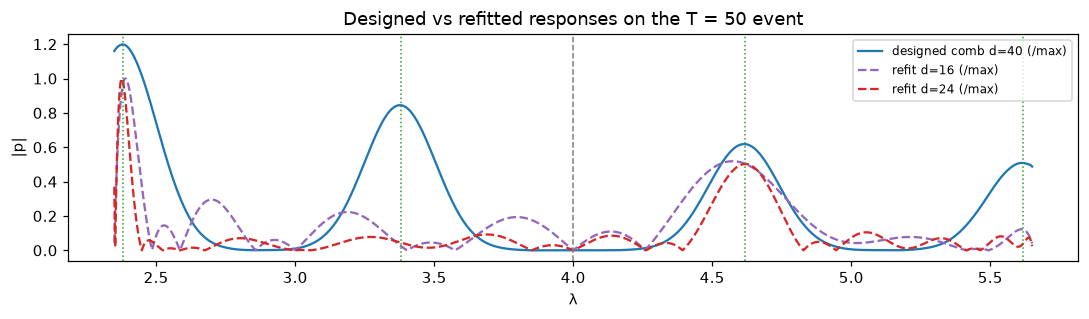

In [33]:
lo, hi = spectral_bounds(A20, pad=0.0)
c0, c1 = 0.5*(hi+lo), 0.5*(hi-lo)*1.02
dom = (c0 - c1, c0 + c1)
M = chebyshev_moments(A20, b20, dom, dmax=40)
def wp95(x): return quantum_metrics_wp(x, x_cls, truth20, target_eff=0.95)
v = wp95(x_qs)
tab = "| polynomial on the T = 50 event | efficiency at the 95 % point | false rate | ridge μ | selection score (eff at far ≤ 1 %) |\n|---|---|---|---|---|\n"
tab += f"| designed comb, degree 40 | {v[eff_k]:.4f} | {v[far_k]:.4f} | — | — |\n"
fits = {}
for d in (16, 24, 40):
    res = refit_coefficients(M, truth20, x_cls, degree=d, domain=dom)
    fits[d] = res
    v = wp95(res.amplitudes)
    tab += f"| coefficients refit, degree {d} | {v[eff_k]:.4f} | {v[far_k]:.4f} | {res.mu:.3g} | {res.eff_at_far:.4f} |\n"
display(Markdown(tab))

# transfer: the degree-24 polynomial fitted on this event, applied verbatim to a different event of the same kind
gen_b = generate_event(50, ME, CN, seed=303)
ham_b, A_b, b_b, _ = build_system(gen_b, ME, CN)
truth_b = truth_from_event(gen_b); x_cls_b = np.abs(ham_b.solve_classicaly())
xb_comb, _ = QSVT(A_b, b_b, degree=40, spectral_bounds=spectral_bounds(A_b)).solve_statevector()
lo_b, hi_b = spectral_bounds(A_b, pad=0.0)
poly24 = fits[24].poly
if lo_b >= poly24.domain[0] and hi_b <= poly24.domain[1]:
    xb_fit, _ = QSVT(A_b, b_b, poly=poly24, spectral_bounds=(lo_b, hi_b), spectrum_pad=0.0).solve_statevector()
    vb_fit = quantum_metrics_wp(xb_fit, x_cls_b, truth_b, target_eff=0.95)
    fit_line = f"| refit degree 24 (fitted on the first event) | {vb_fit[eff_k]:.4f} | {vb_fit[far_k]:.4f} | {vb_fit['tau_wp']:.3f} |\n"
else:
    fit_line = "| refit degree 24 | spectrum of the second event outside the fitted domain | | |\n"
vb_comb = quantum_metrics_wp(xb_comb, x_cls_b, truth_b, target_eff=0.95)
display(Markdown("**Transfer to a second T = 50 event (seed 303), 95 % working points**\n\n| polynomial | efficiency | false rate | threshold |\n|---|---|---|---|\n"
                 f"| designed comb, degree 40 | {vb_comb[eff_k]:.4f} | {vb_comb[far_k]:.4f} | {vb_comb['tau_wp']:.3f} |\n" + fit_line))

lam = np.linspace(dom[0], dom[1], 2000)
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(lam, np.abs(design_line_comb_inverse(40, s=S, domain=dom)(lam)) / 0.35, label="designed comb d=40 (/max)")
for d, col in ((16, "tab:purple"), (24, "tab:red")):
    ax.plot(lam, np.abs(fits[d].poly(lam)) / 0.95, "--", color=col, label=f"refit d={d} (/max)")
for m in p4_lines(S): ax.axvline(m, color="tab:green", ls=":", lw=1)
ax.axvline(S, color="grey", ls="--", lw=1); ax.set_xlabel("λ"); ax.set_ylabel("|p|"); ax.legend(fontsize=8)
ax.set_title("Designed vs refitted responses on the T = 50 event"); fig.tight_layout(); plt.show()

binned refit: 164 bins of width 0.020 over [2.36, 5.64], ridge mu = 0.003


| response | efficiency at the 95 % point | false rate | threshold |
|---|---|---|---|
| binned refit (exact, not realisable as a polynomial) | 1.0000 | 0.0000 | 0.364 |
| the same response realised at degree 16 | 1.0000 | 0.0000 | 0.317 |
| the same response realised at degree 24 | 1.0000 | 0.0000 | 0.321 |
| the same response realised at degree 40 | 1.0000 | 0.0000 | 0.328 |


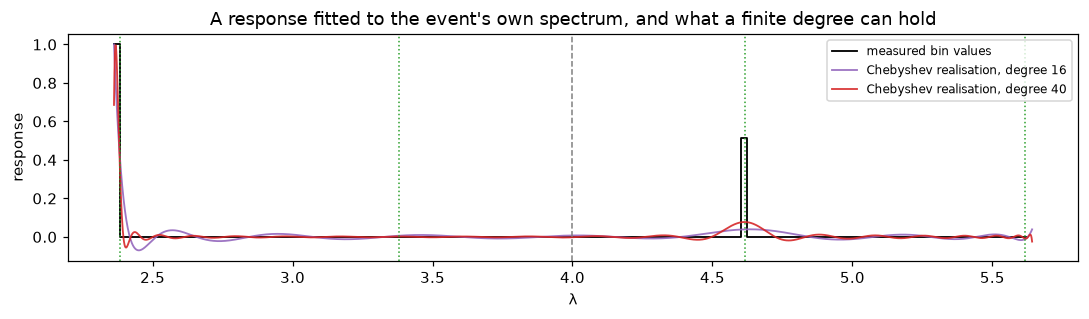

In [34]:
# ── the response as MEASURED bin values, then realised at a finite degree ────
from lhcb_velo_toy.solvers.quantum import (
    refit_binned, binned_response, chebyshev_realize,
)

sysd20 = mode_system(A20, b20, iso_lambda=S)
p_bins, edges, mu_b = refit_binned(sysd20, truth20, x_cls)
dom_b = (float(edges[0]), float(edges[-1]))
print(f"binned refit: {len(p_bins)} bins of width {edges[1]-edges[0]:.3f} over "
      f"[{dom_b[0]:.2f}, {dom_b[1]:.2f}], ridge mu = {mu_b:.3g}")

f_binned = binned_response(p_bins, edges)          # exact, piecewise constant
x_binned = apply_response(sysd20, f_binned)
tab = ("| response | efficiency at the 95 % point | false rate | threshold |\n|---|---|---|---|\n"
       f"| binned refit (exact, not realisable as a polynomial) | "
       f"{wp95(x_binned)[eff_k]:.4f} | {wp95(x_binned)[far_k]:.4f} | {wp95(x_binned)['tau_wp']:.3f} |\n")
realised = {}
for d in (16, 24, 40):
    f_d = chebyshev_realize(f_binned, dom_b, d)     # degree-limited realisation
    realised[d] = f_d
    x_d = apply_response(sysd20, f_d)
    m = wp95(x_d)
    tab += (f"| the same response realised at degree {d} | {m[eff_k]:.4f} | "
            f"{m[far_k]:.4f} | {m['tau_wp']:.3f} |\n")
display(Markdown(tab))

lamg = np.linspace(dom_b[0], dom_b[1], 2000)
fig, ax = plt.subplots(figsize=(10, 3))
ax.step(edges[:-1], p_bins, where="post", color="k", lw=1.2, label="measured bin values")
for d, col in ((16, "tab:purple"), (40, "tab:red")):
    ax.plot(lamg, realised[d](lamg), color=col, lw=1.2, alpha=0.9, label=f"Chebyshev realisation, degree {d}")
for m in p4_lines(S):
    ax.axvline(m, color="tab:green", ls=":", lw=1)
ax.axvline(S, color="grey", ls="--", lw=1)
ax.set_xlabel("λ"); ax.set_ylabel("response"); ax.legend(fontsize=8)
ax.set_title("A response fitted to the event's own spectrum, and what a finite degree can hold")
fig.tight_layout(); plt.show()

---
## 8. Summary

1. **The QSVT is the comb**: a degree-40 polynomial with narrow $1/\lambda$ passes at the four true-track
   lines. On the clean and moderate toy events it keeps the true amplitude profile tight and pushes
   every false failure mode (isolated, pair, triple, hub) to $\approx 0$, where the 1BQF's single
   cosine zero reaches only the isolated line.
2. **One response, three exact evaluators** (`solve_statevector`, `solve_eigh`, `run_circuit`) and
   **three circuit realisations** (LCU of walk powers, the phase sequence, the QETU trigonometric comb)
   with different width / depth / success-probability trade-offs; `resources(realisation)` prices them.
3. **Working points are per solver and efficiency-first**: never judge a filtered spectrum at the
   classical fixed cut. Use `quantum_metrics_wp` (any `target_eff`).
4. **Response families** beyond the comb — band (retired), minimax, normalized comb, the one-bit cosine
   as a series, the trigonometric comb — all run through the same machinery on identical events.
5. **Refitting** the coefficients to a measured event is a supervised diagnostic and the basis of the
   transfer test; it is under audit, not a production filter.

See `README.md` § "Solver lanes", `docs/API_REFERENCE.md` § "QSVT", and `CHANGELOG.md`.

In [35]:
# My first simulated event

N_TRACKS = 5
ME = 0.01
CN = 1e-4
SEED = 123

my_gen = generate_event(
    n_tracks=N_TRACKS,
    measurement_error=ME,
    collision_noise=CN,
    seed=SEED
)

my_ham, my_A, my_b, my_eps = build_system(
    my_gen,
    ME,
    CN
)

my_truth = truth_from_event(my_gen)

print("Number of tracks:", N_TRACKS)
print("Number of candidate segments:", my_ham.n_segments)
print("Number of true segments:", my_truth.sum())
print("Shape of A:", my_A.shape)
print("Shape of b:", my_b.shape)
print("epsilon:", my_eps)

Number of tracks: 5
Number of candidate segments: 100
Number of true segments: 20
Shape of A: (100, 100)
Shape of b: (100,)
epsilon: 0.0031777035588293387


In [36]:
print(my_A.toarray())

[[4. 0. 0. ... 0. 0. 0.]
 [0. 4. 0. ... 0. 0. 0.]
 [0. 0. 4. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 4. 0. 0.]
 [0. 0. 0. ... 0. 4. 0.]
 [0. 0. 0. ... 0. 0. 4.]]


In [37]:
GAMMA = 3.0
DELTA = 1.0
S = GAMMA + DELTA

In [38]:
my_qsvt = QSVT.comb(
    my_A,
    my_b,
    degree=40,
    spectral_bounds=spectral_bounds(my_A)
)

my_x_qsvt, my_p_qsvt = my_qsvt.solve_statevector()

print("QSVT solution:")
print(my_x_qsvt)

print("\nSuccess probability:")
print(my_p_qsvt)

QSVT solution:
[0.19805227 0.00106317 0.00106317 0.00106317 0.00106317 0.00106317
 0.19805227 0.00106317 0.00106317 0.00106317 0.00106317 0.00106317
 0.19805227 0.00106317 0.00106317 0.00106317 0.00106317 0.00106317
 0.19805227 0.00106317 0.00106317 0.00106317 0.00106317 0.00106317
 0.19805227 0.24650813 0.00106317 0.00106317 0.00106317 0.00106317
 0.00106317 0.24650813 0.00106317 0.00106317 0.00106317 0.00106317
 0.00106317 0.24650813 0.00106317 0.00106317 0.00106317 0.00106317
 0.00106317 0.24650813 0.00106317 0.00106317 0.00106317 0.00106317
 0.00106317 0.24650813 0.24650813 0.00106317 0.00106317 0.00106317
 0.00106317 0.00106317 0.24650813 0.00106317 0.00106317 0.00106317
 0.00106317 0.00106317 0.24650813 0.00106317 0.00106317 0.00106317
 0.00106317 0.00106317 0.24650813 0.00106317 0.00106317 0.00106317
 0.00106317 0.00106317 0.24650813 0.19805227 0.00106317 0.00106317
 0.00106317 0.00106317 0.00106317 0.19805227 0.00106317 0.00106317
 0.00106317 0.00106317 0.00106317 0.19805227 0.

In [39]:
my_x_classical = np.abs(my_ham.solve_classicaly())

my_x_qsvt_scaled = rescale_to_signal(
    my_x_qsvt,
    my_x_classical
)

print("Classical:")
print(my_x_classical)

print("\nQSVT:")
print(my_x_qsvt_scaled)

Classical:
[0.36363636 0.25       0.25       0.25       0.25       0.25
 0.36363636 0.25       0.25       0.25       0.25       0.25
 0.36363636 0.25       0.25       0.25       0.25       0.25
 0.36363636 0.25       0.25       0.25       0.25       0.25
 0.36363636 0.45454545 0.25       0.25       0.25       0.25
 0.25       0.45454545 0.25       0.25       0.25       0.25
 0.25       0.45454545 0.25       0.25       0.25       0.25
 0.25       0.45454545 0.25       0.25       0.25       0.25
 0.25       0.45454545 0.45454545 0.25       0.25       0.25
 0.25       0.25       0.45454545 0.25       0.25       0.25
 0.25       0.25       0.45454545 0.25       0.25       0.25
 0.25       0.25       0.45454545 0.25       0.25       0.25
 0.25       0.25       0.45454545 0.36363636 0.25       0.25
 0.25       0.25       0.25       0.36363636 0.25       0.25
 0.25       0.25       0.25       0.36363636 0.25       0.25
 0.25       0.25       0.25       0.36363636 0.25       0.25
 0.25       0

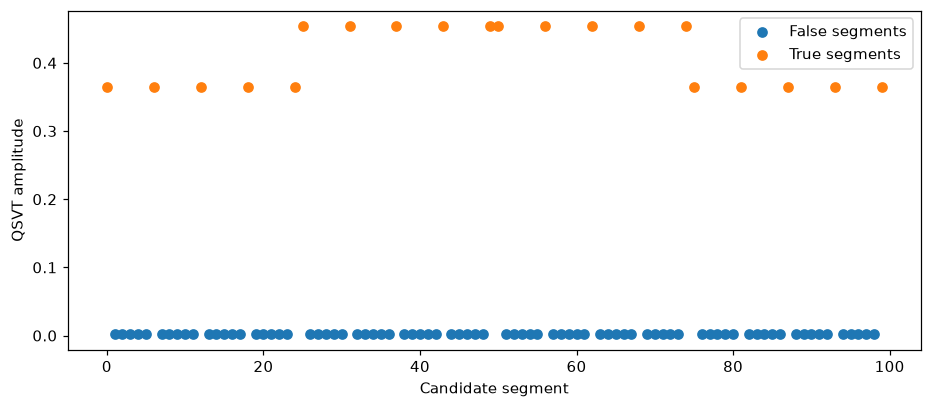

In [40]:
plt.figure(figsize=(10, 4))

plt.scatter(
    np.arange(len(my_x_qsvt_scaled))[~my_truth],
    my_x_qsvt_scaled[~my_truth],
    label="False segments"
)

plt.scatter(
    np.arange(len(my_x_qsvt_scaled))[my_truth],
    my_x_qsvt_scaled[my_truth],
    label="True segments"
)

plt.xlabel("Candidate segment")
plt.ylabel("QSVT amplitude")
plt.legend()
plt.show()

In [41]:
my_tau = quantum_metrics_wp(
    my_x_qsvt,
    my_x_classical,
    my_truth,
    target_eff=0.95
)["tau_wp"]

my_reco = get_tracks(
    my_ham,
    my_x_qsvt_scaled,
    my_gen,
    threshold=my_tau
)

print("QSVT threshold:", my_tau)
print("Number of reconstructed tracks:", len(my_reco))

QSVT threshold: 0.3645849207919202
Number of reconstructed tracks: 5


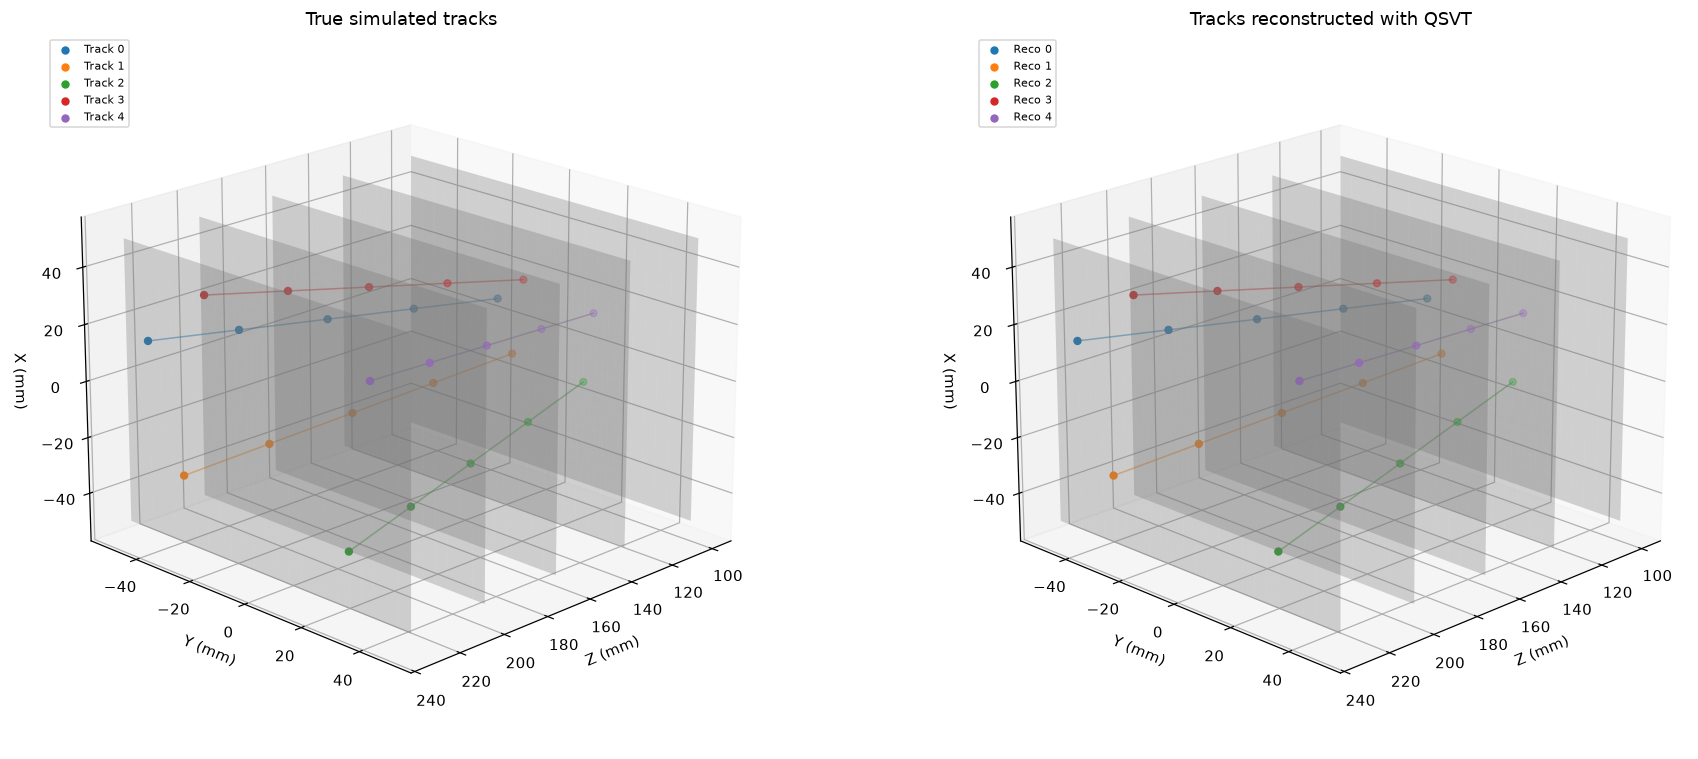

In [42]:
fig = plot_reco_vs_truth(
    my_gen.true_event,
    my_reco,
    title_truth="True simulated tracks",
    title_reco="Tracks reconstructed with QSVT"
)

plt.show()